# Mixture of experts

`probjax.nn.MoELayer` combines a linear router with a bank of SwiGLU experts.
Each token is routed to its `top_k` experts; the router always runs in float32
because top-k selection is precision sensitive.

The layer has three routing strategies:

- `"dense"`: run every expert on every token, then mix with the top-k gates.
  Exact, but `E / top_k` times the compute.
- `"capacity"`: sort assignments into a fixed `[E, C, D]` buffer and drop the
  overflow. Cheap and predictable, but token outputs depend on the batch.
- `"dropless"`: sort rows by expert and run one grouped matmul. Exact like
  dense, without capacity padding or drops.

This notebook compares them and shows the router diagnostics returned by
`return_aux=True`.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx

from probjax.nn import MoELayer

## Setup

Eight experts, top-2 routing, 256 random tokens. Both layers are built with
the same RNG seed so their parameters are identical.

In [2]:
key = jax.random.key(0)
x = jax.random.normal(key, (256, 32))

d_model, d_hidden, num_experts, top_k = 32, 64, 8, 2
dense = MoELayer(
    d_model, d_hidden, num_experts, top_k=top_k, routing="dense", rngs=nnx.Rngs(0)
)
dropless = MoELayer(
    d_model,
    d_hidden,
    num_experts,
    top_k=top_k,
    routing="dropless",
    dropless_impl="blocked",
    rngs=nnx.Rngs(0),
)
print("output shape:", dense(x).shape)
print("dense vs dropless max diff:", float(jnp.max(jnp.abs(dense(x) - dropless(x)))))

output shape: (256, 32)


dense vs dropless max diff: 2.384185791015625e-07


Both paths are exact: the same experts and gates, only the execution strategy
differs. `dropless_impl="blocked"` is the portable implementation; `"auto"`
selects a Pallas grouped-GEMM kernel on supported GPUs.

The timings below are on CPU with the portable blocked path and are not a
performance benchmark; use `"auto"` on a supported GPU for the grouped-GEMM
kernel.

In [3]:
def timed(fn, *args):
    start = time.perf_counter()
    out = jax.block_until_ready(fn(*args))
    return out, time.perf_counter() - start


_, dense_time = timed(jax.jit(dense), x)
_, dropless_time = timed(jax.jit(dropless), x)
print(f"dense    {dense_time * 1e3:7.2f} ms")
print(f"dropless {dropless_time * 1e3:7.2f} ms")

dense     115.21 ms
dropless  233.00 ms


## Capacity routing and overflow

`capacity` is `ceil(capacity_factor * N * K / E)`. With a small factor,
assignments beyond capacity are dropped and `overflow_fraction` grows. A large
factor removes the drops and reproduces the dense output.

In [4]:
tight = MoELayer(
    d_model,
    d_hidden,
    num_experts,
    top_k=top_k,
    routing="capacity",
    capacity_factor=0.5,
    rngs=nnx.Rngs(0),
)
roomy = MoELayer(
    d_model,
    d_hidden,
    num_experts,
    top_k=top_k,
    routing="capacity",
    capacity_factor=4.0,
    rngs=nnx.Rngs(0),
)

y_tight, aux_tight = tight(x, return_aux=True)
y_roomy, aux_roomy = roomy(x, return_aux=True)
print("tight capacity:", aux_tight.capacity, "overflow:", float(aux_tight.overflow_fraction))
print("roomy capacity:", aux_roomy.capacity, "overflow:", float(aux_roomy.overflow_fraction))
print("roomy vs dense max diff:", float(jnp.max(jnp.abs(y_roomy - dense(x)))))

tight capacity: 32 overflow: 0.5
roomy capacity: 256 overflow: 0.0
roomy vs dense max diff: 2.384185791015625e-07


## Router diagnostics

`MoEAux` reports expert counts, utilization, the Switch-style load-balance
loss, a router z-loss, and the capacity statistics. Compare a uniform batch
with a deliberately skewed one: the skewed batch concentrates assignments and
raises the balance loss.

uniform counts: [65 73 61 61 61 48 60 83]
skewed counts:  [119  50  39  23  35  87 108  51]
uniform load-balance loss: 1.0169847011566162
skewed load-balance loss:  1.1939467191696167


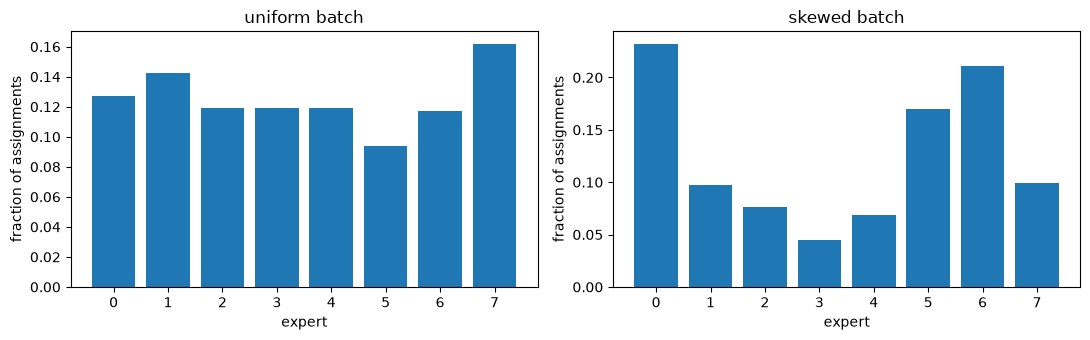

In [5]:
skewed = x + 3.0 * jnp.eye(d_model)[0]  # bias one input direction

_, aux_uniform = dropless(x, return_aux=True)
_, aux_skewed = dropless(skewed, return_aux=True)

print("uniform counts:", jnp.asarray(aux_uniform.expert_counts, dtype=jnp.int32))
print("skewed counts: ", jnp.asarray(aux_skewed.expert_counts, dtype=jnp.int32))
print("uniform load-balance loss:", float(aux_uniform.load_balance_loss))
print("skewed load-balance loss: ", float(aux_skewed.load_balance_loss))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, aux, title in zip(
    axes, (aux_uniform, aux_skewed), ("uniform batch", "skewed batch")
):
    ax.bar(jnp.arange(num_experts), aux.expert_utilization)
    ax.set_xticks(jnp.arange(num_experts))
    ax.set_xlabel("expert")
    ax.set_ylabel("fraction of assignments")
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Shared experts

`shared_hidden` adds a DeepSeekMoE-style dense SwiGLU that every token passes
through, added to the routed output. The routed experts can then be many and
narrow while the shared path carries common knowledge.

In [6]:
shared = MoELayer(
    d_model,
    d_hidden,
    num_experts,
    top_k=top_k,
    routing="dropless",
    dropless_impl="blocked",
    shared_hidden=32,
    rngs=nnx.Rngs(0),
)
y_shared = shared(x)
shared_term = shared.shared(x)
print("shared output shape:", y_shared.shape)
print("shared term norm:", float(jnp.linalg.norm(shared_term)))
print("routed term norm:", float(jnp.linalg.norm(y_shared - shared_term)))

shared output shape: (256, 32)
shared term norm: 60.18947219848633
routed term norm: 42.5783576965332


## Takeaways

- Use `dense` for exact reference behaviour at small expert counts, `dropless`
  for exact routing without capacity drops, and `capacity` when a fixed buffer
  matters more than batch-independent token outputs.
- `return_aux=True` exposes the router statistics you need for a load-balance
  loss, z-loss, or monitoring dashboard.
- `shared_hidden` splits the layer into a dense common path plus fine-grained
  routed experts.
- `token_mask` lets padded tokens stay out of the balance statistics even though
  they are still routed and computed.